# 02 - EDA Data Train

Tujuan: melihat pola keterlambatan pada **data train saja** (pickup sampai
31 Desember 2025). Validation Januari-Maret 2026 dan test April-Juni 2026
tidak dihitung dan tidak ditampilkan.

Semua grafik disimpan di `reports/figures/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 100)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.25,
    "font.size": 10,
})

BIRU = "#2f5d8a"
MERAH = "#b03a2e"
ABU = "#7f8c8d"

# Baca data lalu langsung potong ke train. Baris validation/test tidak dipakai.
semua = pd.read_csv(ROOT / "data" / "clean.csv", parse_dates=["tanggal_pickup"])
train = semua.loc[semua["tanggal_pickup"] <= "2025-12-31"].copy()
del semua

assert train["tanggal_pickup"].max() <= pd.Timestamp("2025-12-31")
assert train["id_resi"].is_unique

print("Baris train :", len(train))
print("Periode     :", train["tanggal_pickup"].min().date(), "sampai", train["tanggal_pickup"].max().date())
print("Rasio target:", round(train["terlambat"].mean(), 4))

Baris train : 26633
Periode     : 2025-01-01 sampai 2025-12-31
Rasio target: 0.1778


## 1. Tingkat keterlambatan per bulan

Grafik ini dipakai untuk melihat drift atau musiman. Garis putus-putus adalah
rata-rata train.

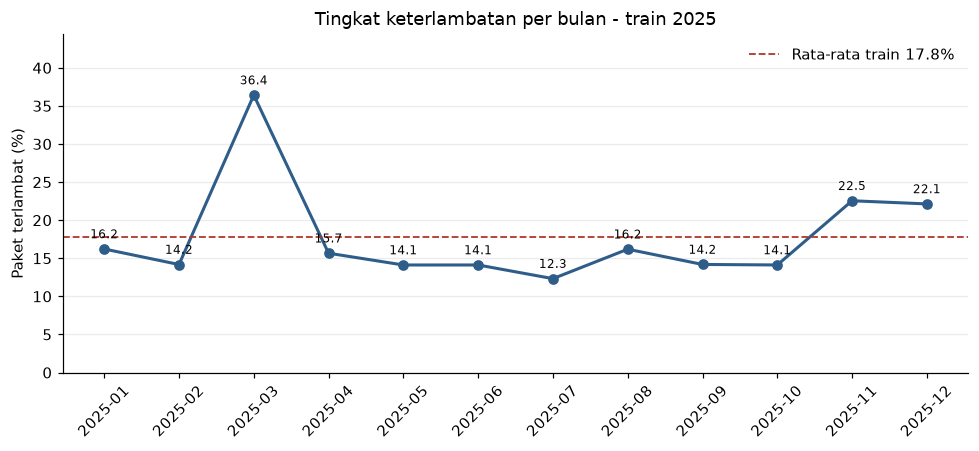

,size,mean
bulan,,
2025-01,2275,0.1622
2025-02,2031,0.1418
2025-03,2301,0.3642
2025-04,2177,0.1566
2025-05,2224,0.1412
2025-06,2160,0.1412
2025-07,2215,0.1233
2025-08,2279,0.1619
2025-09,2206,0.1419


In [2]:
train["bulan"] = train["tanggal_pickup"].dt.strftime("%Y-%m")
bulanan = train.groupby("bulan")["terlambat"].agg(["size", "mean"])

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(bulanan.index, bulanan["mean"] * 100, marker="o", color=BIRU, linewidth=2)
ax.axhline(train["terlambat"].mean() * 100, color=MERAH, linestyle="--", linewidth=1.2,
           label=f"Rata-rata train {train['terlambat'].mean():.1%}")
for x, y in zip(bulanan.index, bulanan["mean"] * 100):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 7),
                ha="center", fontsize=8)
ax.set_title("Tingkat keterlambatan per bulan - train 2025")
ax.set_ylabel("Paket terlambat (%)")
ax.set_xlabel("")
ax.set_ylim(0, max(bulanan["mean"] * 100) + 8)
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_tren_bulanan.png", dpi=160, bbox_inches="tight")
plt.show()

bulanan.round(4)

## 2. Layanan dan metode bayar

Layanan menentukan SLA, sedangkan COD diperiksa karena proses pembayaran bisa
menambah waktu operasional.

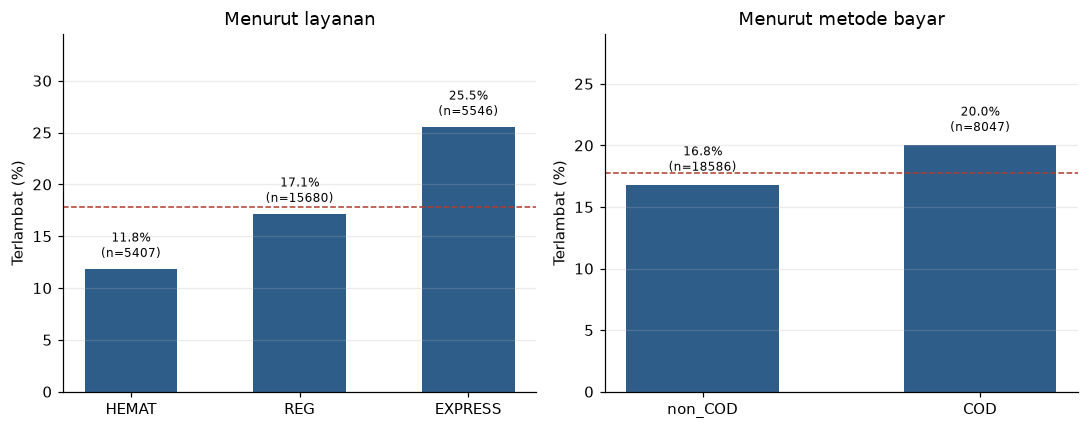

In [3]:
layanan = train.groupby("layanan")["terlambat"].agg(["size", "mean"]).sort_values("mean")
metode = train.groupby("metode_bayar")["terlambat"].agg(["size", "mean"]).sort_values("mean")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, tabel, judul in [
    (axes[0], layanan, "Menurut layanan"),
    (axes[1], metode, "Menurut metode bayar"),
]:
    ax.bar(tabel.index, tabel["mean"] * 100, color=BIRU, width=0.55)
    ax.axhline(train["terlambat"].mean() * 100, color=MERAH, linestyle="--", linewidth=1)
    for i, (nama, baris) in enumerate(tabel.iterrows()):
        ax.text(i, baris["mean"] * 100 + 0.8, f"{baris['mean']:.1%}\n(n={int(baris['size'])})",
                ha="center", va="bottom", fontsize=8)
    ax.set_title(judul)
    ax.set_ylabel("Terlambat (%)")
    ax.set_ylim(0, max(tabel["mean"] * 100) + 9)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_layanan_metode.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Kota tujuan

Kota diurutkan dari tingkat keterlambatan tertinggi. Semua kota punya sampel
lebih dari 800 paket di train.

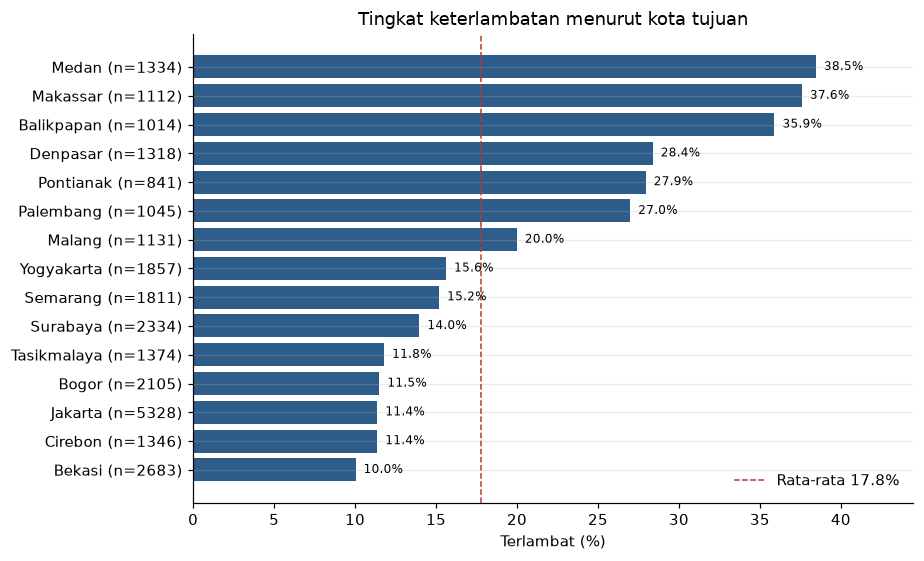

In [4]:
kota = train.groupby("kota_tujuan")["terlambat"].agg(["size", "mean"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(8.5, 5.2))
label = [f"{k} (n={int(n)})" for k, n in zip(kota.index, kota["size"])]
ax.barh(label, kota["mean"] * 100, color=BIRU)
ax.axvline(train["terlambat"].mean() * 100, color=MERAH, linestyle="--", linewidth=1,
           label=f"Rata-rata {train['terlambat'].mean():.1%}")
for i, nilai in enumerate(kota["mean"] * 100):
    ax.text(nilai + 0.5, i, f"{nilai:.1f}%", va="center", fontsize=8)
ax.set_title("Tingkat keterlambatan menurut kota tujuan")
ax.set_xlabel("Terlambat (%)")
ax.set_xlim(0, max(kota["mean"] * 100) + 6)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_kota.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Cuaca saat pickup dan jam pickup

Cuaca hilang ditampilkan sebagai `tidak diketahui` agar tidak menyembunyikan
masalah data. Jam 17-22 diberi warna berbeda karena polanya berbeda dari siang.

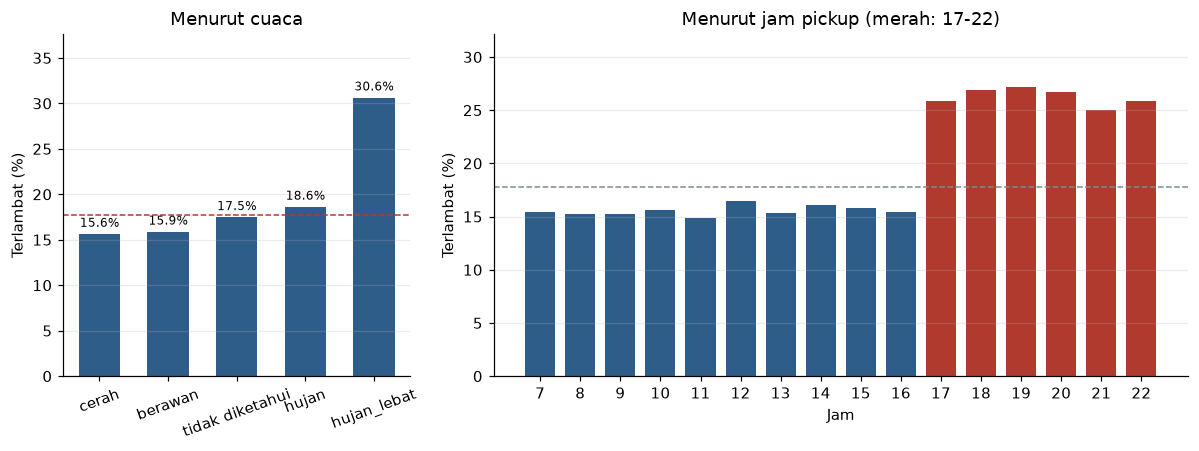

In [5]:
cuaca = (train["cuaca_saat_pickup"].fillna("tidak diketahui")
         .to_frame(name="cuaca")
         .assign(terlambat=train["terlambat"])
         .groupby("cuaca")["terlambat"].agg(["size", "mean"]).sort_values("mean"))
jam = train.groupby("jam_pickup")["terlambat"].agg(["size", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 2]})

axes[0].bar(cuaca.index, cuaca["mean"] * 100, color=BIRU, width=0.6)
axes[0].axhline(train["terlambat"].mean() * 100, color=MERAH, linestyle="--", linewidth=1)
for i, baris in enumerate(cuaca.itertuples()):
    axes[0].text(i, baris.mean * 100 + 0.8, f"{baris.mean:.1%}", ha="center", fontsize=8)
axes[0].set_title("Menurut cuaca")
axes[0].set_ylabel("Terlambat (%)")
axes[0].set_ylim(0, max(cuaca["mean"] * 100) + 7)
axes[0].tick_params(axis="x", rotation=20)

warna_jam = [MERAH if h >= 17 else BIRU for h in jam.index]
axes[1].bar(jam.index, jam["mean"] * 100, color=warna_jam, width=0.75)
axes[1].axhline(train["terlambat"].mean() * 100, color=ABU, linestyle="--", linewidth=1)
axes[1].set_xticks(range(7, 23))
axes[1].set_title("Menurut jam pickup (merah: 17-22)")
axes[1].set_xlabel("Jam")
axes[1].set_ylabel("Terlambat (%)")
axes[1].set_ylim(0, max(jam["mean"] * 100) + 5)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_cuaca_jam.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Jumlah transit dan volume hub

`volume_hub_hari` dibagi menjadi beberapa kelompok agar tingkat keterlambatan
mudah dibaca. Batas 9.000 mengikuti hasil audit data sebelumnya.

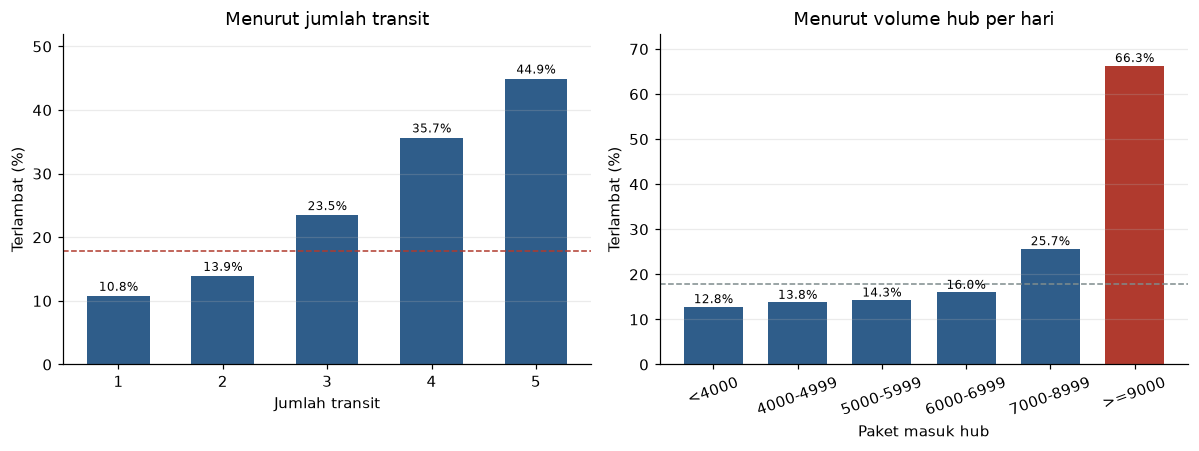

,size,mean
jumlah_transit,,
1.0,10987,0.1078
2.0,6976,0.1390
3.0,4594,0.2347
4.0,3544,0.3567
5.0,532,0.4492


In [6]:
bins = [0, 4000, 5000, 6000, 7000, 9000, 10**9]
label_volume = ["<4000", "4000-4999", "5000-5999", "6000-6999", "7000-8999", ">=9000"]
train["volume_bin"] = pd.cut(train["volume_hub_hari"], bins=bins, labels=label_volume, right=False)

transit = train.groupby("jumlah_transit")["terlambat"].agg(["size", "mean"])
volume = train.groupby("volume_bin", observed=False)["terlambat"].agg(["size", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(transit.index.astype(int).astype(str), transit["mean"] * 100, color=BIRU, width=0.6)
axes[0].axhline(train["terlambat"].mean() * 100, color=MERAH, linestyle="--", linewidth=1)
for i, baris in enumerate(transit.itertuples()):
    axes[0].text(i, baris.mean * 100 + 0.8, f"{baris.mean:.1%}", ha="center", fontsize=8)
axes[0].set_title("Menurut jumlah transit")
axes[0].set_xlabel("Jumlah transit")
axes[0].set_ylabel("Terlambat (%)")
axes[0].set_ylim(0, max(transit["mean"] * 100) + 7)

warna_volume = [MERAH if label == ">=9000" else BIRU for label in volume.index.astype(str)]
axes[1].bar(volume.index.astype(str), volume["mean"] * 100, color=warna_volume, width=0.7)
axes[1].axhline(train["terlambat"].mean() * 100, color=ABU, linestyle="--", linewidth=1)
for i, baris in enumerate(volume.itertuples()):
    axes[1].text(i, baris.mean * 100 + 0.8, f"{baris.mean:.1%}", ha="center", fontsize=8)
axes[1].set_title("Menurut volume hub per hari")
axes[1].set_xlabel("Paket masuk hub")
axes[1].set_ylabel("Terlambat (%)")
axes[1].set_ylim(0, max(volume["mean"] * 100) + 7)
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_transit_volume.png", dpi=160, bbox_inches="tight")
plt.show()

transit.round(4)

## Temuan utama

1. **Volume hub sangat kuat, tetapi berisiko bocor.** Kelompok `>=9000` punya
   tingkat terlambat 66,3%, jauh di atas kelompok lain (12,8%-25,7%). Korelasi
   dengan target 0,31. Namun definisi kolom adalah total paket **sehari penuh**;
   saat pickup, total itu belum tentu diketahui. Lihat catatan kebocoran di bawah.
2. **Transit, jarak/kota, dan layanan saling terkait.** Transit 1 hari: 10,8%,
   transit 5 hari: 44,9%. Kota jauh seperti Medan 38,5%, Makassar 37,6%, dan
   Balikpapan 35,9% juga tinggi. EXPRESS 25,5% versus HEMAT 11,8%.
3. **Cuaca dan jam pickup memberi sinyal tambahan.** Hujan lebat 30,6% versus
   cerah 15,6%. Pickup jam 17-22 sekitar 25%-27%, sedangkan siang sekitar
   15%-16%. COD 20,0% versus non_COD 16,8%.
4. **Tren bulanan tidak stabil.** Maret 36,4%, November-Desember sekitar 22%,
   bulan lain sekitar 12%-16%. Ini bisa musiman atau lonjakan operasional;
   split berdasarkan waktu tetap penting.

## Apakah `volume_hub_hari` bocor?

Berpotensi **ya**. Kolom ini berarti jumlah paket yang masuk hub pada hari itu.
Jika nilainya adalah total akhir hari, angka tersebut baru lengkap setelah
pickup, sehingga memakai total final berarti memakai informasi masa depan.

Dua pilihan yang aman:
- pakai hitungan berjalan sampai waktu pickup, atau
- pakai volume hari sebelumnya (lag 1 hari).

Jika aplikasi hanya bisa meminta angka total harian final, fitur ini sebaiknya
tidak dipakai pada model final. Keputusan ini perlu dikunci sebelum Tahap B.

## Masalah data yang masih terbuka (hanya train)

Angka di bawah dihitung pada train, bukan seluruh data.

Catatan: `cuaca_saat_pickup` yang kosong tidak dijadikan kategori baru; nilainya diisi modus (`most_frequent`) yang di-fit pada train, dan `flag_cuaca_missing` menandai baris yang sebelumnya kosong.

In [7]:
terbuka = pd.DataFrame(
    [
        ["jarak_km kosong", int(train["jarak_km"].isna().sum()),
         "Biarkan NaN; imputasi setelah split"],
        ["cuaca_saat_pickup kosong", int(train["cuaca_saat_pickup"].isna().sum()),
         "Biarkan NaN; imputasi/kategori khusus setelah split"],
        ["berat_kg tidak wajar", int(train["flag_berat_invalid"].sum()),
         "Sudah NaN; 877 di antaranya kehilangan info karena >100 kg/negatif"],
        ["janji_hari tidak sesuai layanan", int(train["flag_janji_tidak_sesuai"].sum()),
         "Hanya ditandai; belum diubah"],
        ["volume_hub_hari >9000", int(train["flag_volume_ekstrem"].sum()),
         "Masih dipakai; cek apakah lonjakan nyata atau anomali"],
        ["kota hasil pemetaan alias", int(train["flag_kota_alias"].sum()),
         "Sudah dipetakan; asumsi Bali ke Denpasar tetap dicatat"],
        ["layanan hasil pemetaan alias", int(train["flag_layanan_alias"].sum()),
         "Sudah dipetakan; kategori akhir sudah bersih"],
    ],
    columns=["Masalah", "Baris train", "Status"],
)
terbuka

,Masalah,Baris train,Status
0,jarak_km kosong,500,Biarkan NaN; imputasi setelah split
1,cuaca_saat_pickup kosong,252,Biarkan NaN; imputasi/kategori khusus setelah ...
2,berat_kg tidak wajar,877,Sudah NaN; 877 di antaranya kehilangan info ka...
3,janji_hari tidak sesuai layanan,182,Hanya ditandai; belum diubah
4,volume_hub_hari >9000,1625,Masih dipakai; cek apakah lonjakan nyata atau ...
5,kota hasil pemetaan alias,748,Sudah dipetakan; asumsi Bali ke Denpasar tetap...
6,layanan hasil pemetaan alias,395,Sudah dipetakan; kategori akhir sudah bersih


## Catatan

- Grafik: 5 file di `reports/figures/`, masih di bawah batas 6.
- `berat_kg` perlu perhatian: 877 baris train menjadi NaN karena aturan
  `>100 kg`; bisa jadi sebenarnya satuan gram, tetapi belum dikoreksi.
- Tidak ada duplikat `id_resi`; kategori `layanan`, `metode_bayar`, dan
  `cuaca_saat_pickup` sudah konsisten setelah pembersihan.
- Validation dan test belum dilihat.